Paso 1. Instalación de dependencias
En este paso instalamos las librerías necesarias para realizar el proyecto de Web Scraping.
- pandas: permite organizar y procesar los datos en tablas.
- requests: permite realizar peticiones HTTP para descargar el contenido de una página web.
- lxml: permite analizar el HTML de la página y extraer las tablas.

In [1]:
pip install pandas requests lxml

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 43.5 MB/s eta 0:00:00:00:0100:01

[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Importación de librerías
import requests
import pandas as pd
import sqlite3

from io import StringIO

In [3]:
# Descargar el HTML de Wikipedia

import requests
import pandas as pd
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_most-streamed_songs_on_Spotify"

headers = {
    "User-Agent": (
        "WebScrapingStudentProject/1.0 "
        "(educational project; contact: student@example.com)"
    )
}

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

print("Código de estado:", response.status_code)

if response.status_code == 200:
    html = response.text
    print("HTML descargado correctamente.")
    print("Longitud del HTML:", len(html))
else:
    print("No se pudo descargar la página.")
    print(response.text[:500])

Código de estado: 200
HTML descargado correctamente.
Longitud del HTML: 1348563


In [4]:
#Comprobar el contenido descargado
# Comprobar la respuesta del servidor
print("Código de estado:", response.status_code)
print("URL final:", response.url)
print("Longitud del HTML:", len(html))
print("Contenido recibido:")
print(html[:1000])

Código de estado: 200
URL final: https://en.wikipedia.org/wiki/List_of_most-streamed_songs_on_Spotify
Longitud del HTML: 1348563
Contenido recibido:
<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard skin-underline-clientpref-browser" lang="en" dir="ltr">
<head>
<meta charset="UTF-8">
<title>List of Spotify streaming records - Wikipedia</title>
<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-

In [5]:
#Transformar el HTML
tables = pd.read_html(StringIO(html))

print("Número de tablas encontradas:", len(tables))

Número de tablas encontradas: 30


In [6]:
df = tables[0]

display(df.head())

print("Columnas disponibles:")
print(df.columns.tolist())

,Rank,Song,Artist(s),Streams (billions),Release date,Ref.
0,1,"""Blinding Lights""",The Weeknd,5.644,29 November 2019,[1]
1,2,"""Shape Of You""",Ed Sheeran,5.152,6 January 2017,[2]
2,3,"""Sweater Weather""",The Neighbourhood,4.970,3 December 2012,[3]
3,4,"""Starboy""",The Weeknd and Daft Punk,4.824,21 September 2016,[4]
4,5,"""As It Was""",Harry Styles,4.681,1 April 2022,[5]


Columnas disponibles:
['Rank', 'Song', 'Artist(s)', 'Streams (billions)', 'Release date', 'Ref.']


In [7]:
#Procesamiento y limpieza de datos
# Revisar la estructura
df.info()

print("Valores ausentes:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Rank                101 non-null    str  
 1   Song                101 non-null    str  
 2   Artist(s)           101 non-null    str  
 3   Streams (billions)  101 non-null    str  
 4   Release date        101 non-null    str  
 5   Ref.                97 non-null     str  
dtypes: str(6)
memory usage: 4.9 KB
Valores ausentes:
Rank                  0
Song                  0
Artist(s)             0
Streams (billions)    0
Release date          0
Ref.                  4
dtype: int64


In [8]:
# Mostrar los nombres originales
print(df.columns.tolist())

['Rank', 'Song', 'Artist(s)', 'Streams (billions)', 'Release date', 'Ref.']


In [9]:
# Asignar nombres uniformes a las columnas
df.columns = [
    "Rank",
    "Song",
    "Artist",
    "Streams (billions)",
    "Date released",
    "Reference"
]

# Limpiar nombres de canciones y artistas
df["Song"] = (
    df["Song"].astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.strip()
)

df["Artist"] = (
    df["Artist"].astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.strip()
)

# Convertir las reproducciones a números
df["Streams (billions)"] = pd.to_numeric(
    df["Streams (billions)"],
    errors="coerce"
)

# Convertir las fechas
df["Date released"] = pd.to_datetime(
    df["Date released"],
    errors="coerce"
)

# Eliminar filas sin información esencial y duplicados
df = df.dropna(
    subset=["Song", "Artist", "Streams (billions)"]
)

df = df.drop_duplicates()

display(df.head())

print("Total de registros:", len(df))

,Rank,Song,Artist,Streams (billions),Date released,Reference
0,1,"""Blinding Lights""",The Weeknd,5.644,2019-11-29,[1]
1,2,"""Shape Of You""",Ed Sheeran,5.152,2017-01-06,[2]
2,3,"""Sweater Weather""",The Neighbourhood,4.970,2012-12-03,[3]
3,4,"""Starboy""",The Weeknd and Daft Punk,4.824,2016-09-21,[4]
4,5,"""As It Was""",Harry Styles,4.681,2022-04-01,[5]


Total de registros: 100


In [10]:
# Importar las librerías para visualizar los datos
import matplotlib.pyplot as plt
import seaborn as sns

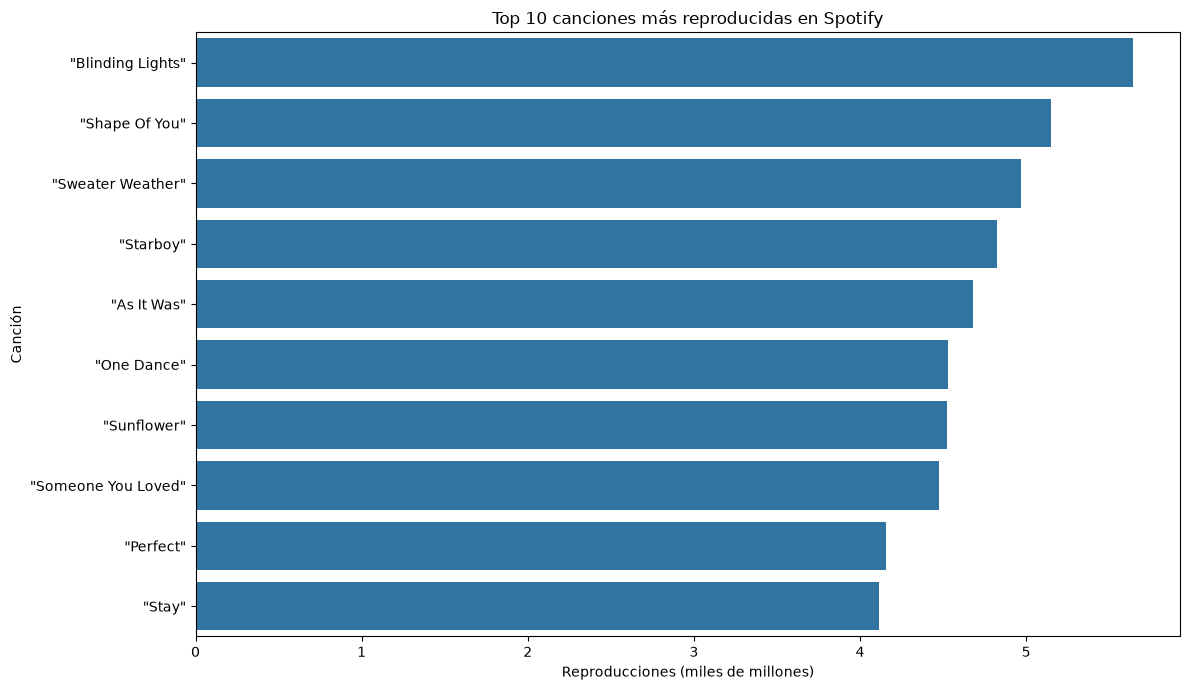

In [11]:
# Seleccionar las 10 canciones con más reproducciones
top_10 = df.nlargest(10, "Streams (billions)").copy()

# Crear el gráfico
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10,
    x="Streams (billions)",
    y="Song"
)

plt.title("Top 10 canciones más reproducidas en Spotify")
plt.xlabel("Reproducciones (miles de millones)")
plt.ylabel("Canción")

plt.tight_layout()
plt.show()

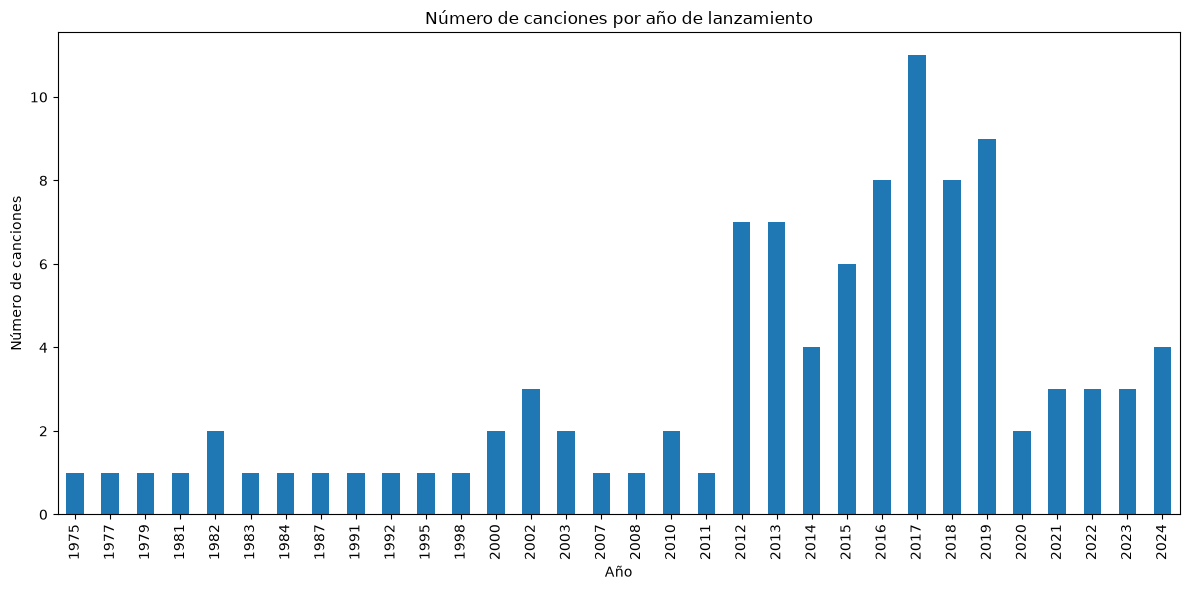

In [12]:
# Extraer el año de lanzamiento
df["Year"] = df["Date released"].dt.year

# Contar canciones por año
songs_by_year = df["Year"].value_counts().sort_index()

# Crear el gráfico
plt.figure(figsize=(12, 6))

songs_by_year.plot(kind="bar")

plt.title("Número de canciones por año de lanzamiento")
plt.xlabel("Año")
plt.ylabel("Número de canciones")

plt.tight_layout()
plt.show()

In [13]:
#. Almacenamiento de datos en SQLite
import sqlite3

# Crear la conexión con la base de datos
conn = sqlite3.connect("spotify_top_songs.db")

# Guardar el DataFrame en una tabla
df.to_sql(
    "most_streamed",
    conn,
    if_exists="replace",
    index=False
)

# Confirmar los cambios
conn.commit()

print("Datos guardados correctamente.")

Datos guardados correctamente.


Conclusión

En este proyecto he aprendido a extraer, limpiar, almacenar y visualizar datos mediante Web Scraping. Durante el proceso surgieron dificultades con el acceso a Wikipedia, que devolvía un error 403, y con algunas dependencias de Python. Estos contratiempos me permitieron practicar la resolución de errores y comprender la importancia de verificar los datos y las herramientas utilizadas.